In [5]:
import pandas as pd

data = {
    "area_sqft": [800,950,1100,1250,1400,1550,1700,1850,2000,2150,
                  2300,2450,2600,2750,2900,3050,3200,3350,3500,3650],

    "bedrooms": [2,2,2,3,3,3,3,3,4,4,4,4,4,4,5,5,5,5,5,5],

    "age_years": [10,8,5,7,4,12,6,3,8,5,2,10,4,7,3,9,4,6,2,8],

    "distance_km": [8,6,5,7,4,9,5,3,6,4,3,8,5,6,2,7,4,5,3,6],

    "price_inr": [4200000,5100000,6300000,6900000,8500000,
                  7900000,9800000,11500000,11200000,12900000,
                  14800000,13500000,15800000,16000000,18500000,
                  17400000,19800000,20500000,22500000,21800000]
}

df = pd.DataFrame(data)

df.to_csv("house_prices.csv", index=False)

print("Dataset created successfully!")

Dataset created successfully!


In [7]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   --------- ------------------------------ 2.4/9.5 MB 14.7 MB/s eta 0:00:01
   -------------------------- ------------- 6.3/9.5 MB 15.0 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 16.8 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 11.9 MB/s  0:00:00

   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- --

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
%pip install pandas numpy scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -------- ------------------------------- 1.8/8.4 MB 13.2 MB/s eta 0:00:01
   -------------------------- ------------- 5.5/8.4 MB 15.9 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 14.9 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   - -------------------------------------- 1.8/37.4 MB 10.2 MB/s eta 0:00:04
   --- ------------------------------------ 3.4/37.4 MB 9.6 MB/s eta 0:00:04
   ----- ---------------------------------- 4.7/37.4 MB 8.2 MB/s eta 0:00:04
   ------ --------------------------------- 6.0/37.4 MB 7.4 MB/s eta 0:00:05
   ------- -------------------------------- 7.1/37.4 MB 7.0 MB/s eta 0:00:05
   -------- ------------------------------- 7.9/37.4 MB 6.2 MB/s eta 0:00:05
   -------- ------------------------------- 8.4/37.4 MB 5.8 MB/s eta 0:00:05
   --------- ------------------------------ 9.2/37.4 MB 5.4 MB/s eta 0:00:06
   ---------- --


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# 1. Import libraries and inspect data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

df = pd.read_csv("house_prices.csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical description:")
print(df.describe())

First five rows:
   area_sqft  bedrooms  age_years  distance_km  price_inr
0        800         2         10            8    4200000
1        950         2          8            6    5100000
2       1100         2          5            5    6300000
3       1250         3          7            7    6900000
4       1400         3          4            4    8500000

Dataset shape:
(20, 5)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   area_sqft    20 non-null     int64
 1   bedrooms     20 non-null     int64
 2   age_years    20 non-null     int64
 3   distance_km  20 non-null     int64
 4   price_inr    20 non-null     int64
dtypes: int64(5)
memory usage: 932.0 bytes

Missing values:
area_sqft      0
bedrooms       0
age_years      0
distance_km    0
price_inr      0
dtype: int64

Statistical description:
         area_sqft   bedrooms  age

In [ ]:
# 1. Separate features and target

X = df[[
    "area_sqft",
    "bedrooms",
    "age_years",
    "distance_km"
]]

y = df["price_inr"]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Input features:
   area_sqft  bedrooms  age_years  distance_km
0        800         2         10            8
1        950         2          8            6
2       1100         2          5            5
3       1250         3          7            7
4       1400         3          4            4

Target values:
0    4200000
1    5100000
2    6300000
3    6900000
4    8500000
Name: price_inr, dtype: int64


In [ ]:
# 2. Create train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16, 4)
Testing data: (4, 4)


In [ ]:
# 3. Create the model evaluation function

def evaluate_model(features, model_name):

    # Select required features
    X_train_selected = X_train[features]
    X_test_selected = X_test[features]

    # Create model
    model = LinearRegression()

    # Train model
    model.fit(X_train_selected, y_train)

    # Predict test data
    predictions = model.predict(X_test_selected)

    # Calculate metrics
    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    print("\n", model_name)
    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R2 Score:", r2)

    return {
        "Model": model_name,
        "Features": features,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "model_object": model,
        "predictions": predictions
    }

In [5]:
# Model A: Simple Linear Regression
model_A = evaluate_model(
    ["area_sqft"],
    "Model A - Baseline"
)

# Model B: Multiple Linear Regression
model_B = evaluate_model(
    ["area_sqft", "bedrooms", "age_years", "distance_km"],
    "Model B - All Features"
)

# Model C: Selected Features
model_C = evaluate_model(
    ["area_sqft", "bedrooms"],
    "Model C - Selected Features"
)


 Model A - Baseline
MAE: 418258.9353038764
MSE: 418715036601.7558
RMSE: 647081.9396349706
R2 Score: 0.9920130655869956

 Model B - All Features
MAE: 486840.85248108127
MSE: 331867787489.0358
RMSE: 576079.671129815
R2 Score: 0.9936696654746965

 Model C - Selected Features
MAE: 477446.4359291317
MSE: 487206338453.2512
RMSE: 698001.6751077687
R2 Score: 0.9907066029861087


In [ ]:
# 4. Compares all three models

results = pd.DataFrame([
    {
        "Model": model_A["Model"],
        "Features": model_A["Features"],
        "MAE": model_A["MAE"],
        "RMSE": model_A["RMSE"],
        "R2": model_A["R2"]
    },
    {
        "Model": model_B["Model"],
        "Features": model_B["Features"],
        "MAE": model_B["MAE"],
        "RMSE": model_B["RMSE"],
        "R2": model_B["R2"]
    },
    {
        "Model": model_C["Model"],
        "Features": model_C["Features"],
        "MAE": model_C["MAE"],
        "RMSE": model_C["RMSE"],
        "R2": model_C["R2"]
    }
])

print(results.round(2))

                         Model                                       Features  \
0           Model A - Baseline                                    [area_sqft]   
1       Model B - All Features  [area_sqft, bedrooms, age_years, distance_km]   
2  Model C - Selected Features                          [area_sqft, bedrooms]   

         MAE       RMSE    R2  
0  418258.94  647081.94  0.99  
1  486840.85  576079.67  0.99  
2  477446.44  698001.68  0.99  


In [ ]:
# 5. Calculate residuals

# Get Model B predictions
predictions = model_B["predictions"]

# Calculate residuals
residuals = y_test.values - predictions

# Create residual dataframe
residual_df = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": predictions,
    "Residual": residuals
})

print(residual_df.round(2))

   Actual Price  Predicted Price   Residual
0       4200000       3209734.79  990265.21
1      20500000      20340964.81  159035.19
2      17400000      17759652.01 -359652.01
3       5100000       4661589.00  438411.00


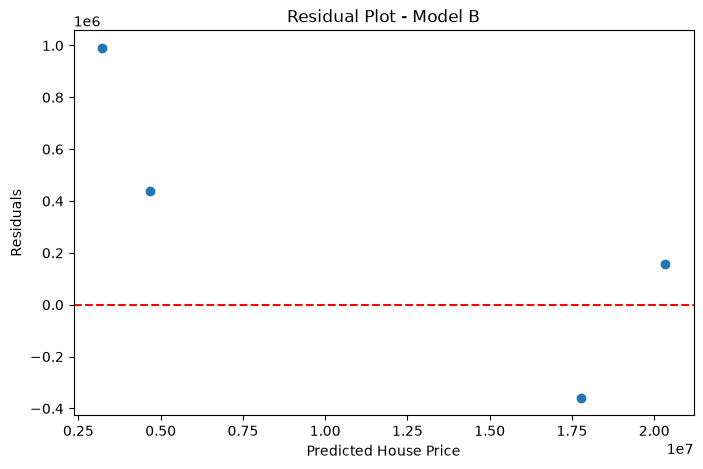

In [ ]:
# 5. Plot residuals

plt.figure(figsize=(8, 5))

plt.scatter(
    predictions,
    residuals
)

# Horizontal reference line
plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted House Price")
plt.ylabel("Residuals")

plt.title("Residual Plot - Model B")

plt.show()

In [ ]:
# 6. find the three largest errors

# Create a dataframe with test features and residuals
error_df = X_test.copy()

error_df["Actual Price"] = y_test.values
error_df["Predicted Price"] = predictions
error_df["Residual"] = residuals

error_df["Absolute Residual"] = abs(residuals)

# Sort by largest absolute residual
largest_errors = error_df.sort_values(
    by="Absolute Residual",
    ascending=False
)

print("Three Largest Errors:")

print(largest_errors.head(3).round(2))

Three Largest Errors:
    area_sqft  bedrooms  age_years  distance_km  Actual Price  \
0         800         2         10            8       4200000   
1         950         2          8            6       5100000   
15       3050         5          9            7      17400000   

    Predicted Price   Residual  Absolute Residual  
0        3209734.79  990265.21          990265.21  
1        4661589.00  438411.00          438411.00  
15      17759652.01 -359652.01          359652.01  
